# Notebook 2: Closing the Superposition Gap with a Concept Adapter (ours)

**Course project: Foundations of LLMs (AI60213)** · Base paper: *Soft Thinking* (Zhang et al., NeurIPS 2025)

**Notebook 1** implemented Soft Thinking and measured its limitation, the **superposition gap**. This notebook contains **our method**: a small trainable **concept adapter** that recalibrates each concept token before the frozen LLM reads it. We train it without labels, run Soft Thinking + adapter on the *same* 250 GSM8K test questions, and compare it with the paper's method.

**Contents**

0. Briefing: the method and its design
1. Setup, including Notebook 1's results
2. Shared machinery (identical to Notebook 1)
3. The concept adapter
4. Training: traces and adapter training
5. Evaluation: Soft Thinking + adapter on GSM8K
6. Comparison: paper vs adapter
7. Conclusion

---
# Part 0: Briefing

## 0.1 Goal

Notebook 1 found that at each mixed thinking step the model reads the concept token $\tilde{\mathbf e}_t$ mostly as its top-1 candidate, far from the superposition Soft Thinking intends:

$$\underbrace{h(\tilde{\mathbf{e}}_t)}_{\text{what the model does with the mixture}} \quad\text{vs.}\quad \underbrace{\textstyle\sum_k c_t[k]\; h(\mathbf{e}(k))}_{\text{the superposition Soft Thinking intends}}$$

**Goal:** move the model's response toward the intended superposition **without changing the LLM** and **without hurting accuracy**.

## 0.2 The concept adapter

$$\mathbf y = \tilde{\mathbf e}_t + s_t\cdot W_{\text{up}}\,\mathrm{GELU}\!\big(W_{\text{down}}\,\tilde{\mathbf e}_t / s_t\big), \qquad s_t = \mathrm{RMS}(\tilde{\mathbf e}_t)$$

$$\mathbf e'_t = \mathbf y \cdot \min\!\Big(1,\ \frac{\sum_k c_k\|\mathbf e(k)\|}{\|\mathbf y\|}\Big)$$

* **Small.** Rank 64, about 0.26M parameters, against 1.7B frozen.
* **Applied only to genuinely mixed concept tokens.** Ordinary tokens pass through unchanged.
* **Norm cap.** The input can never exceed the norm of a real token at that step, so the adapter cannot push inputs out of the embedding scale.
* **Starts as the paper's method.** $W_{\text{up}}$ is zero-initialised, and $\|\tilde{\mathbf e}_t\| \le \sum_k c_k \|\mathbf e(k)\|$ always holds (triangle inequality), so the cap is inactive at initialisation. Before training, the adapter *is* vanilla Soft Thinking.

## 0.3 Training objective: layer-wise superposition

$$\mathcal L = \frac{1}{L+1}\sum_{\ell=0}^{L} \frac{\big\|h_\ell(\mathbf e'_t) - \sum_k c_k\, h_\ell(\mathbf e(k))\big\|^2}{\big\|\sum_k c_k\, h_\ell(\mathbf e(k))\big\|^2}$$

The design choices behind it:

* **Every layer, not just the output.** Each input also writes keys and values at every layer, and all later tokens attend to them. Matching only the next-token prediction would leave those unconstrained.
* **No hedging.** At the last layer the target is a superposition of *logits*, i.e. a geometric (product-of-experts) mixture of next-token distributions. That mixture stays sharp instead of rewarding a spread-out prediction.
* **Built-in trust region.** Layer $\ell = 0$ is the input itself, so its term keeps $\mathbf e'_t$ close to $\tilde{\mathbf e}_t$, with no extra weight to tune.
* **Self-supervised.** Targets come from the frozen model's own responses to each candidate. No labels or answers are used, and the LLM stays frozen.
* **Optimisation.** AdamW with learning rate $10^{-3}$, cosine schedule, 3 epochs, gradient clipping at 1.0.

## 0.4 Protocol and runtime (one T4)

1. **Traces.** Run vanilla Soft Thinking on 400 GSM8K **training** questions; 90% are used for training and 10% for validation.
2. **Train** the adapter.
3. **On-policy check.** Decode 16 held-out training questions with the adapter, to catch any instability before the long test run.
4. **Evaluate** on the 250 test questions with settings identical to Notebook 1.
5. **Compare** with Notebook 1's results on the same questions, question by question.

| Step | QUICK | FULL |
|---|---|---|
| Load model + Notebook 1 results | ~2 min | ~2 min |
| Traces on training questions | ~10 min (32) | ~2 h (400) |
| Adapter training | ~1 min (1 epoch) | ~20 min (3 epochs) |
| On-policy check | ~5 min | ~5 min |
| Test evaluation + diagnosis | ~6 min (16) | ~85 min (250) |
| **Total** | **~25 min** | **~4 h** |

**On Kaggle:** choose *Add Input → Notebooks (Your Work)* → select Notebook 1 (a version that finished in FULL mode). The setup cell finds its output automatically.

---
# Part 1: Setup

In [1]:
#!pip install -q -U "transformers>=4.51" accelerate datasets

In [2]:
# Optional: a Hugging Face token avoids download rate limits (Kaggle: Add-ons -> Secrets -> HF_TOKEN).
# from kaggle_secrets import UserSecretsClient; import os
# os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")

In [3]:
import os, re, glob, json, math, time, random, pickle
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset

RUN_MODE = "FULL"      # "QUICK": short smoke test | "FULL": the reported numbers
SEED = 0

@dataclass
class Config:
    n_test: int = 250               # first n GSM8K test questions
    batch_size: int = 16            # questions decoded in parallel
    # Soft Thinking settings (identical in both notebooks)
    max_think_tokens: int = 2048
    max_answer_tokens: int = 512
    temperature: float = 0.6
    top_k: int = 15
    top_p: float = 0.95
    min_p: float = 0.001
    cold_stop: bool = True
    cold_stop_tau: float = 0.01
    cold_stop_len: int = 128
    # Diagnosis
    max_probe_steps: int = 64       # mixed steps probed per trace (memory cap)
    # Concept adapter
    n_train: int = 400              # GSM8K training questions for traces (no labels used)
    adapter_rank: int = 64
    adapter_lr: float = 1e-3
    adapter_epochs: int = 3
    val_frac: float = 0.1
    grad_clip: float = 1.0
    n_policy_check: int = 16        # held-out training questions decoded with the adapter before the test run

CFG = Config() if RUN_MODE == "FULL" else Config(n_test=16, n_train=32, adapter_epochs=1)

OUT_DIR = ("/kaggle/working" if os.path.isdir("/kaggle/working") else ".") + f"/concept_adapter_{RUN_MODE.lower()}"
os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    # A T4 (compute capability 7.5) has no native bfloat16, so float16 is used there.
    DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DTYPE = torch.float32
    print("No GPU found: FULL mode is not practical on CPU.")
print(f"RUN_MODE={RUN_MODE} | dtype={DTYPE} | outputs -> {OUT_DIR}")
print("torch", torch.__version__, "| transformers", transformers.__version__)
CFG

GPU: Tesla T4
RUN_MODE=FULL | dtype=torch.float16 | outputs -> /kaggle/working/concept_adapter_full
torch 2.11.0+cu130 | transformers 5.20.2


Config(n_test=250, batch_size=16, max_think_tokens=2048, max_answer_tokens=512, temperature=0.6, top_k=15, top_p=0.95, min_p=0.001, cold_stop=True, cold_stop_tau=0.01, cold_stop_len=128, max_probe_steps=64, n_train=400, adapter_rank=64, adapter_lr=0.001, adapter_epochs=3, val_frac=0.1, grad_clip=1.0, n_policy_check=16)

## 1.1 Notebook 1's results

We use the paper's results on the same test questions (`soft_test.pkl`), their gap diagnosis (`diag_paper.pkl`) and the decoding time. A FULL run of Notebook 1 is preferred; in QUICK mode the first `n_test` questions are used.

In [4]:
def find_nb1_dir():
    for mode in ("full", "quick"):
        for root in ("/kaggle/input", "."):
            hits = sorted(glob.glob(f"{root}/**/soft_thinking_paper_{mode}/soft_test.pkl", recursive=True))
            if hits:
                return os.path.dirname(hits[0])
    return None

NB1_DIR = find_nb1_dir()
assert NB1_DIR is not None, ("Notebook 1's output was not found. On Kaggle: Add Input -> Notebooks (Your Work) -> "
                             "select Notebook 1 (a finished run that contains soft_thinking_paper_full/).")
with open(f"{NB1_DIR}/soft_test.pkl", "rb") as f:
    paper_test = pickle.load(f)[:CFG.n_test]
with open(f"{NB1_DIR}/diag_paper.pkl", "rb") as f:
    _ids = {r["id"] for r in paper_test}
    diag_paper = pickle.load(f).query("id in @_ids").reset_index(drop=True)
paper_time = json.load(open(f"{NB1_DIR}/soft_test_time.json")) if os.path.exists(f"{NB1_DIR}/soft_test_time.json") else None
test_set = [{"id": r["id"], "q": r["q"], "a": r["gold"]} for r in paper_test]
print("Notebook 1 output:", NB1_DIR)
print(f"paper results: {len(paper_test)} test questions | paper diagnosis: {len(diag_paper)} mixed steps")

Notebook 1 output: /kaggle/input/notebooks/anarvaaa/fllm-project-nb1/soft_thinking_paper_full
paper results: 250 test questions | paper diagnosis: 15909 mixed steps


## 1.2 Model and training questions

In [5]:
MODEL_NAME = "Qwen/Qwen3-1.7B"

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
tok.padding_side = "left"                                  # batched decoding
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
_dtype_kw = "dtype" if tuple(int(x) for x in transformers.__version__.split(".")[:2]) >= (4, 56) else "torch_dtype"
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **{_dtype_kw: DTYPE}).to(DEVICE).eval()
model.requires_grad_(False)                                # the LLM is always frozen

E = model.get_input_embeddings().weight                    # (vocab, d): input embedding matrix
D_MODEL = E.shape[1]
N_LAYERS = model.config.num_hidden_layers
END_THINK_ID = tok.convert_tokens_to_ids("</think>")
assert tok.decode([END_THINK_ID]) == "</think>", "model has no </think> token: use a reasoning model"
EOS_IDS = {i for i in {tok.eos_token_id, tok.convert_tokens_to_ids("<|im_end|>")} if i is not None}
EOS_ID = min(EOS_IDS)
FORCE_IDS = tok("</think>\n\n", add_special_tokens=False).input_ids   # appended when thinking ends
print(f"E: {tuple(E.shape)} | layers: {N_LAYERS} | </think> = {END_THINK_ID} | eos = {EOS_IDS} | "
      f"frozen params: {sum(p.numel() for p in model.parameters())/1e9:.2f}B")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

E: (151936, 2048) | layers: 28 | </think> = 151668 | eos = {151645} | frozen params: 1.72B


In [6]:
def gsm_gold(answer: str) -> float:
    return float(answer.split("####")[-1].strip().replace(",", ""))

gsm_train = load_dataset("openai/gsm8k", "main")["train"]
train_idx = random.Random(SEED).sample(range(len(gsm_train)), CFG.n_train)
train_set = [{"id": int(i), "q": gsm_train[int(i)]["question"], "a": gsm_gold(gsm_train[int(i)]["answer"])}
             for i in train_idx]
print(f"training questions (traces only, answers unused for training): {len(train_set)}")

README.md:   0%|          | 0.00/7.93k [00:00<?, ?B/s]

main/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.31MB            

main/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

main/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  419kB            

main/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

training questions (traces only, answers unused for training): 400


---
# Part 2: Shared machinery

The code in this part is **identical to Notebook 1**: concept tokens, the batched Soft Thinking loop (now called with `adapter=...`), the runner, and the gap diagnosis with probe tokens. See Notebook 1, Parts 3–4, for the explanations.

In [7]:
def concept_tokens(logits: torch.Tensor, cfg: Config = CFG):
    """logits (B, V) -> concept-token weights (B, K) summing to 1 (zeros = filtered out) and their ids (B, K).
    Column 0 is always the argmax."""
    probs = torch.softmax(logits / cfg.temperature, dim=-1)
    p, ids = probs.topk(cfg.top_k, dim=-1)
    keep = (p.cumsum(-1) - p) < cfg.top_p                        # top-p on the true probabilities
    keep &= p >= cfg.min_p * p[:, :1]                            # min-p relative to the argmax
    keep[:, 0] = True
    p = p * keep
    return p / p.sum(-1, keepdim=True), ids


def entropies(p: torch.Tensor) -> torch.Tensor:
    """H(c_t) for Cold Stop."""
    return -(p * p.clamp_min(1e-12).log()).sum(-1)


def soft_embeddings(p: torch.Tensor, ids: torch.Tensor) -> torch.Tensor:
    """e~_t = sum_k c_t[k] e(k), computed in fp32."""
    return torch.einsum("bk,bkd->bd", p.float(), E[ids].float())


def candidate_norm(p: torch.Tensor, ids: torch.Tensor) -> torch.Tensor:
    """sum_k c_t[k] ||e(k)||: the norm a real token would have at this step."""
    return (p.float() * E[ids].float().norm(dim=-1)).sum(-1)


def build_prompt(question: str) -> str:
    msgs = [{"role": "user",
             "content": question + "\nPlease reason step by step, and put your final answer within \\boxed{}."}]
    text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=True)
    if not text.rstrip().endswith("<think>"):
        text += "<think>\n"
    return text


def extract_boxed(text: str):
    """Content of the last \\boxed{...}; falls back to the last number in the text."""
    start = text.rfind("\\boxed{")
    if start == -1:
        nums = re.findall(r"-?\d[\d,]*\.?\d*", text)
        return nums[-1] if nums else None
    i, depth, buf = start + len("\\boxed{"), 1, []
    while i < len(text):
        depth += {"{": 1, "}": -1}.get(text[i], 0)
        if depth == 0:
            break
        buf.append(text[i]); i += 1
    return "".join(buf)


def to_number(s):
    if s is None:
        return None
    nums = re.findall(r"-?\d+\.?\d*", s.replace(",", ""))
    return float(nums[0]) if nums else None

In [8]:
THINK, FORCE, ANSWER, DONE = range(4)

@torch.no_grad()
def soft_think_batch(questions, cfg: Config = CFG, adapter=None):
    """Batched Soft Thinking. If `adapter` is given, it is applied as adapter(e~, weights, ids) to every
    genuinely mixed concept token (>= 2 surviving candidates) before it is fed to the model."""
    enc = tok([build_prompt(q) for q in questions], return_tensors="pt", padding=True).to(DEVICE)
    mask = enc.attention_mask
    pos = (mask.cumsum(-1) - 1).clamp_min(0)                    # left padding: explicit positions
    out = model(input_ids=enc.input_ids, attention_mask=mask, position_ids=pos, use_cache=True, logits_to_keep=1)
    past, logits, next_pos = out.past_key_values, out.logits[:, -1].float(), pos[:, -1] + 1

    B = len(questions)
    phase, queue, low_run = [THINK] * B, [[] for _ in range(B)], [0] * B
    recs = [{"steps": [], "answer_ids": [], "stop_reason": None} for _ in range(B)]
    while True:
        p, cids = concept_tokens(logits, cfg)
        H = entropies(p)
        p_c, ids_c, H_c = p.cpu(), cids.cpu(), H.cpu()
        token_ids, soft_rows = [EOS_ID] * B, []
        for b in range(B):
            if phase[b] == THINK:
                keep = p_c[b] > 0
                step = {"ids": ids_c[b][keep].tolist(), "probs": p_c[b][keep].tolist(), "entropy": float(H_c[b])}
                recs[b]["steps"].append(step)
                low_run[b] = low_run[b] + 1 if step["entropy"] < cfg.cold_stop_tau else 0
                if step["ids"][0] == END_THINK_ID or step["ids"][0] in EOS_IDS:
                    reason = "</think>"
                elif cfg.cold_stop and low_run[b] >= cfg.cold_stop_len:
                    reason = "cold stop"
                elif len(recs[b]["steps"]) >= cfg.max_think_tokens:
                    reason = "budget"
                else:
                    soft_rows.append(b)
                    continue
                recs[b]["stop_reason"] = reason                # the stopping step itself is never fed
                phase[b], queue[b] = FORCE, list(FORCE_IDS)
            if phase[b] == FORCE:
                token_ids[b] = queue[b].pop(0)
                if not queue[b]:
                    phase[b] = ANSWER
            elif phase[b] == ANSWER:
                nxt = int(ids_c[b][0])                         # greedy answer token
                if nxt in EOS_IDS or len(recs[b]["answer_ids"]) >= cfg.max_answer_tokens:
                    phase[b] = DONE
                else:
                    recs[b]["answer_ids"].append(nxt)
                    token_ids[b] = nxt
        if all(ph == DONE for ph in phase):
            break
        emb = E[torch.tensor(token_ids, device=DEVICE)].clone()
        if soft_rows:
            r = torch.tensor(soft_rows, device=DEVICE)
            se = soft_embeddings(p[r], cids[r])
            if adapter is not None:
                mixed = (p[r] > 0).sum(-1) > 1
                se = torch.where(mixed[:, None], adapter(se, p[r], cids[r]), se)
            emb[r] = se.to(E.dtype)
        mask = torch.cat([mask, mask.new_ones(B, 1)], dim=1)
        out = model(inputs_embeds=emb[:, None], attention_mask=mask, position_ids=next_pos[:, None],
                    past_key_values=past, use_cache=True, logits_to_keep=1)
        past, logits, next_pos = out.past_key_values, out.logits[:, -1].float(), next_pos + 1
    return recs

In [9]:
def save_pkl(obj, name):
    with open(f"{OUT_DIR}/{name}.pkl", "wb") as f:
        pickle.dump(obj, f)


def load_pkl(name, folder=None):
    path = f"{folder or OUT_DIR}/{name}.pkl"
    if not os.path.exists(path):
        return None
    with open(path, "rb") as f:
        return pickle.load(f)


def run_soft_thinking(data, name, cfg: Config = CFG, adapter=None):
    """Decode `data` in batches, parse answers, save results (with every concept token) and the wall time."""
    cached = load_pkl(name)
    if cached is not None:
        print(f"[{name}] loaded {len(cached)} cached results")
        return cached
    results, t_start = [], time.time()
    for i in range(0, len(data), cfg.batch_size):
        batch = data[i:i + cfg.batch_size]
        t0 = time.time()
        recs = soft_think_batch([ex["q"] for ex in batch], cfg, adapter)
        for ex, r in zip(batch, recs):
            answer = tok.decode(r["answer_ids"], skip_special_tokens=True).strip()
            pred = to_number(extract_boxed(answer))
            results.append({"id": ex["id"], "q": ex["q"], "gold": ex["a"], "pred": pred,
                            "correct": pred is not None and abs(pred - ex["a"]) < 1e-4,
                            "think_tokens": len(r["steps"]), "stop_reason": r["stop_reason"],
                            "answer": answer, "steps": r["steps"]})
        acc = np.mean([x["correct"] for x in results])
        print(f"[{name}] {len(results):4d}/{len(data)} | batch {time.time()-t0:6.1f}s | "
              f"elapsed {(time.time()-t_start)/60:5.1f} min | running acc {acc:.3f}")
    save_pkl(results, name)
    with open(f"{OUT_DIR}/{name}_time.json", "w") as f:
        json.dump({"seconds": time.time() - t_start, "questions": len(data)}, f)
    return results


def tail_repetition(r, n=4, tail=256):
    """Fraction of repeated 4-grams in the last 256 argmax thinking tokens (0 = no repetition, ~1 = a loop)."""
    ids = [s["ids"][0] for s in r["steps"]][-tail:]
    grams = [tuple(ids[i:i + n]) for i in range(len(ids) - n + 1)]
    return 1 - len(set(grams)) / len(grams) if grams else 0.0


def summarize(results, label):
    fed = [s for r in results for s in r["steps"][:-1]]
    return {
        "system": label,
        "accuracy": np.mean([r["correct"] for r in results]),
        "avg think tokens": np.mean([r["think_tokens"] for r in results]),
        "stop: </think>": np.mean([r["stop_reason"] == "</think>" for r in results]),
        "stop: cold stop": np.mean([r["stop_reason"] == "cold stop" for r in results]),
        "stop: budget": np.mean([r["stop_reason"] == "budget" for r in results]),
        "no \\boxed answer": np.mean(["\\boxed{" not in r["answer"] for r in results]),
        "mixed steps": np.mean([len(s["ids"]) > 1 for s in fed]) if fed else float("nan"),
        "tail repetition": np.mean([tail_repetition(r) for r in results]),
    }

In [10]:
def trace_tensors(steps):
    """Dense (T, K) weights / ids of the concept tokens that were FED (all but the stopping step)."""
    fed = steps[:-1]
    T, K = len(fed), max((len(s["ids"]) for s in fed), default=1)
    P = torch.zeros(T, K, device=DEVICE)
    C = torch.zeros(T, K, dtype=torch.long, device=DEVICE)
    for t, s in enumerate(fed):
        P[t, :len(s["ids"])] = torch.tensor(s["probs"], device=DEVICE)
        C[t, :len(s["ids"])] = torch.tensor(s["ids"], device=DEVICE)
    return P, C


def trace_inputs(question, steps, adapter=None):
    """Exactly what the model was fed: prompt embeddings + one (soft, possibly adapted) embedding per step."""
    prompt_ids = tok(build_prompt(question), return_tensors="pt").input_ids[0].to(DEVICE)
    P, C = trace_tensors(steps)
    se = soft_embeddings(P, C)
    support = (P > 0).sum(-1)
    fed = se if adapter is None else torch.where((support > 1)[:, None], adapter(se, P, C), se)
    return torch.cat([E[prompt_ids], fed.to(E.dtype)]), len(prompt_ids), P, C, support, se


def pick_mixed_steps(support, cap, seed=SEED):
    idx = (support > 1).nonzero().squeeze(-1)
    if len(idx) > cap:
        g = torch.Generator().manual_seed(seed)
        idx = idx[torch.randperm(len(idx), generator=g)[:cap].to(idx.device)].sort().values
    return idx


def probe_mask(L, positions):
    """(1,1,Q,L+Q) mask: probe j sees cached keys < positions[j] and itself, nothing else."""
    Q = len(positions)
    m = torch.zeros(Q, L + Q, dtype=torch.bool, device=DEVICE)
    m[:, :L] = torch.arange(L, device=DEVICE)[None, :] < positions[:, None]
    m[torch.arange(Q, device=DEVICE), L + torch.arange(Q, device=DEVICE)] = True
    return m[None, None]


def flatten_candidates(P, C, t_idx, P0):
    """One row per (mixed step, candidate): token id, weight, owning step, absolute position."""
    sel = P[t_idx] > 0
    owner = torch.arange(len(t_idx), device=DEVICE)[:, None].expand_as(sel)[sel]
    return C[t_idx][sel], P[t_idx][sel], owner, (P0 + t_idx)[owner]


def superpose(hidden_states, w, owner, M):
    """Per layer l: sum_k c_k h_l(e(k)) for every mixed step -> list of (M, d) fp32 tensors."""
    return [torch.zeros(M, D_MODEL, device=DEVICE).index_add_(0, owner, w[:, None] * h[0].float())
            for h in hidden_states]


@torch.no_grad()
def mixture_target(h_cand, w, owner, M, chunk=256):
    """q_t = sum_k c_k softmax(lm_head(h(e(k)))): the intended next-token distribution, (M, V) fp32."""
    q = torch.zeros(M, model.lm_head.out_features, device=DEVICE)
    for i in range(0, len(owner), chunk):
        probs = torch.softmax(model.lm_head(h_cand[i:i + chunk].to(DTYPE)).float(), dim=-1)
        q.index_add_(0, owner[i:i + chunk], w[i:i + chunk, None] * probs)
    return q


def kl_to_target(q, logits):
    logp = F.log_softmax(logits.float(), dim=-1)
    return (q * (q.clamp_min(1e-12).log() - logp)).sum(-1)


@torch.no_grad()
def diagnose_trace(res, adapter=None, cap=CFG.max_probe_steps):
    """All gap metrics for up to `cap` mixed steps of one finished trace (two forward passes)."""
    X, P0, P, C, support, se = trace_inputs(res["q"], res["steps"], adapter)
    t_idx = pick_mixed_steps(support, cap)
    if len(t_idx) == 0:
        return None
    out = model.model(inputs_embeds=X[None], use_cache=True, output_hidden_states=True)      # pass 1: real trace
    L = X.shape[0]
    cand, w, owner, pos = flatten_candidates(P, C, t_idx, P0)
    probe = model.model(inputs_embeds=E[cand][None], attention_mask=probe_mask(L, pos), position_ids=pos[None],
                        past_key_values=out.past_key_values, output_hidden_states=True)       # pass 2: probes
    M, rows = len(t_idx), P0 + t_idx
    targets = superpose(probe.hidden_states, w, owner, M)
    h_soft = [h[0, rows].float() for h in out.hidden_states]
    rel = torch.stack([(hs - tg).norm(dim=-1) / tg.norm(dim=-1) for hs, tg in zip(h_soft, targets)])   # (L+1, M)
    h_last = probe.hidden_states[-1][0].float()
    first = torch.cat([torch.zeros(1, dtype=torch.long, device=DEVICE), (owner[1:] != owner[:-1]).nonzero().squeeze(-1) + 1])
    q = mixture_target(h_last, w, owner, M)
    logits_soft = model.lm_head(h_soft[-1].to(DTYPE))
    x_in = X[rows].float()
    df = pd.DataFrame({
        "id": res["id"], "correct": res["correct"], "step": t_idx.cpu().numpy(),
        "entropy": [res["steps"][int(t)]["entropy"] for t in t_idx],
        "support": support[t_idx].cpu().numpy(),
        "norm_ratio": (x_in.norm(dim=-1) / candidate_norm(P[t_idx], C[t_idx])).cpu().numpy(),
        "input_shift": ((x_in - se[t_idx]).norm(dim=-1) / se[t_idx].norm(dim=-1)).cpu().numpy(),
        "gap_layers": rel[1:].mean(0).cpu().numpy(),
        "gap_hidden": rel[-1].cpu().numpy(),
        "dist_top1": ((h_soft[-1] - h_last[first]).norm(dim=-1) / h_last[first].norm(dim=-1)).cpu().numpy(),
        "kl_output": kl_to_target(q, logits_soft).cpu().numpy(),
        "argmax_agree": (logits_soft.argmax(-1) == q.argmax(-1)).cpu().numpy(),
    })
    for l in range(rel.shape[0]):
        df[f"gap_L{l}"] = rel[l].cpu().numpy()
    return df


def diagnose_run(results, name, adapter=None):
    cached = load_pkl(name)
    if cached is not None:
        print(f"[{name}] loaded cached diagnosis")
        return cached
    t0 = time.time()
    diag = pd.concat([d for d in (diagnose_trace(r, adapter) for r in results) if d is not None], ignore_index=True)
    print(f"[{name}] {len(diag)} mixed steps from {diag['id'].nunique()} traces in {time.time()-t0:.0f}s")
    save_pkl(diag, name)
    return diag


def diag_summary(diag, label):
    return {
        "system": label,
        "mixed steps probed": len(diag),
        "norm ratio (mean)": diag["norm_ratio"].mean(),
        "input shift (mean)": diag["input_shift"].mean(),
        "gap, all layers (mean)": diag["gap_layers"].mean(),
        "gap, final layer (mean)": diag["gap_hidden"].mean(),
        "dist to top-1, final layer (mean)": diag["dist_top1"].mean(),
        "closer to top-1 than to superposition": (diag["dist_top1"] < diag["gap_hidden"]).mean(),
        "output KL (mean)": diag["kl_output"].mean(),
        "output KL (median)": diag["kl_output"].median(),
        "argmax agrees with mixture": diag["argmax_agree"].mean(),
    }

In [11]:
# Sanity check: probe hidden states (every layer) must equal brute-force recomputation of each prefix.
@torch.no_grad()
def check_probes(res, n=3):
    X, P0, P, C, support, se = trace_inputs(res["q"], res["steps"])
    t_idx = pick_mixed_steps(support, n)
    out = model.model(inputs_embeds=X[None], use_cache=True)
    cand, w, owner, pos = flatten_candidates(P, C, t_idx, P0)
    hs = model.model(inputs_embeds=E[cand][None], attention_mask=probe_mask(X.shape[0], pos), position_ids=pos[None],
                     past_key_values=out.past_key_values, output_hidden_states=True).hidden_states
    errs = []
    for j in range(len(cand)):
        ref = model.model(inputs_embeds=torch.cat([X[:pos[j]], E[cand[j]][None]])[None], output_hidden_states=True).hidden_states
        errs += [((h[0, j].float() - r[0, -1].float()).norm() / r[0, -1].float().norm()).item() for h, r in zip(hs, ref)]
    print(f"probe vs brute force over {len(cand)} probes x {len(hs)} layers: max relative error = {max(errs):.2e}")
    assert max(errs) < 5e-2, "probe trick disagrees with recomputation: check the transformers version (4D masks)"

check_probes(next(r for r in paper_test if any(len(s["ids"]) > 1 for s in r["steps"][:-1])))

probe vs brute force over 7 probes x 29 layers: max relative error = 3.49e-03


---
# Part 3: The concept adapter

In [12]:
class ConceptAdapter(nn.Module):
    """e' = cap( e + s * Up(GELU(Down(e / s))) ),  s = RMS(e),  ||e'|| <= sum_k c_k ||e(k)||.
    Up is zero-initialised, so the adapter starts as the identity (= the paper's Soft Thinking)."""
    def __init__(self, d: int, rank: int):
        super().__init__()
        self.down, self.up = nn.Linear(d, rank), nn.Linear(rank, d)
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)

    def forward(self, e, p, ids):
        x = e.float()
        s = x.pow(2).mean(-1, keepdim=True).sqrt().clamp_min(1e-6)
        y = x + s * self.up(F.gelu(self.down(x / s)))
        cap = candidate_norm(p, ids)[:, None]
        return y * torch.clamp(cap / y.norm(dim=-1, keepdim=True).clamp_min(1e-6), max=1.0)


# Check: an untrained adapter leaves every concept token unchanged.
_r = next(r for r in paper_test if any(len(s["ids"]) > 1 for s in r["steps"][:-1]))
_P, _C = trace_tensors(_r["steps"])
_se = soft_embeddings(_P, _C)
_a = ConceptAdapter(D_MODEL, CFG.adapter_rank).to(DEVICE)
assert torch.allclose(_a(_se, _P, _C), _se, rtol=1e-5, atol=1e-6)
N_ADAPTER_PARAMS = sum(p.numel() for p in _a.parameters())
print(f"adapter parameters: {N_ADAPTER_PARAMS:,} | identity at initialisation: OK")

adapter parameters: 264,256 | identity at initialisation: OK


## 3.1 Loss: layer-wise superposition

For one training trace:

1. A no-grad pass over the trace, as generated by Soft Thinking, builds the KV cache.
2. A no-grad **probe pass** gives $h_\ell(\mathbf e(k))$ for every candidate at every layer. The targets are $\sum_k c_k h_\ell(\mathbf e(k))$.
3. A **gradient pass** feeds the adapted inputs $\mathbf e'_t$ at the same positions with the same probe mask.
4. The loss is the relative squared error averaged over steps and layers $0..L$. Only the adapter receives gradients.

For monitoring we also report the output KL to the arithmetic mixture on validation traces. The adapter does not optimise it.

In [13]:
def adapter_loss(res, adapter, cap=CFG.max_probe_steps, seed=SEED, with_kl=False):
    with torch.no_grad():
        X, P0, P, C, support, se = trace_inputs(res["q"], res["steps"], adapter=None)
        t_idx = pick_mixed_steps(support, cap, seed=seed)
        if len(t_idx) == 0:
            return None
        cache, L = model.model(inputs_embeds=X[None], use_cache=True).past_key_values, X.shape[0]
        cand, w, owner, cpos = flatten_candidates(P, C, t_idx, P0)
        probe = model.model(inputs_embeds=E[cand][None], attention_mask=probe_mask(L, cpos), position_ids=cpos[None],
                            past_key_values=cache, output_hidden_states=True)
        M = len(t_idx)
        targets = superpose(probe.hidden_states, w, owner, M)
        q = mixture_target(probe.hidden_states[-1][0], w, owner, M) if with_kl else None
        L_now = L + len(cand)                 # probes were appended to the cache; the mask below hides them
    pos = P0 + t_idx
    e_ad = adapter(se[t_idx], P[t_idx], C[t_idx])
    out = model.model(inputs_embeds=e_ad.to(E.dtype)[None], attention_mask=probe_mask(L_now, pos),
                      position_ids=pos[None], past_key_values=cache, output_hidden_states=True)
    loss = torch.stack([((h[0].float() - tg).pow(2).sum(-1) / tg.pow(2).sum(-1).clamp_min(1e-6)).mean()
                        for h, tg in zip(out.hidden_states, targets)]).mean()
    if with_kl:
        return loss, kl_to_target(q, model.lm_head(out.hidden_states[-1][0])).mean()
    return loss


@torch.no_grad()
def evaluate_adapter(adapter, items):
    vals = [v for v in (adapter_loss(r, adapter, with_kl=True) for r in items) if v is not None]
    return float(np.mean([v[0].item() for v in vals])), float(np.mean([v[1].item() for v in vals]))

---
# Part 4: Training

## 4.1 Training traces

We run vanilla Soft Thinking (the paper's method) on the training questions. Only the traces are used; the answers never are.

In [14]:
train_traces = run_soft_thinking(train_set, "train_traces")
items = [r for r in train_traces if any(len(s["ids"]) > 1 for s in r["steps"][:-1])]
random.Random(SEED).shuffle(items)
n_val = max(1, int(len(items) * CFG.val_frac))
val_items, fit_items = items[:n_val], items[n_val:]
print(f"traces with mixed steps: {len(items)} | fit: {len(fit_items)} | validation: {len(val_items)}")

[train_traces]   16/400 | batch  325.5s | elapsed   5.4 min | running acc 0.938
[train_traces]   32/400 | batch  323.4s | elapsed  10.8 min | running acc 0.875
[train_traces]   48/400 | batch  318.4s | elapsed  16.1 min | running acc 0.854
[train_traces]   64/400 | batch  309.3s | elapsed  21.3 min | running acc 0.828
[train_traces]   80/400 | batch  305.1s | elapsed  26.4 min | running acc 0.850
[train_traces]   96/400 | batch  317.5s | elapsed  31.7 min | running acc 0.854
[train_traces]  112/400 | batch  288.4s | elapsed  36.5 min | running acc 0.866
[train_traces]  128/400 | batch  320.2s | elapsed  41.8 min | running acc 0.859
[train_traces]  144/400 | batch  294.3s | elapsed  46.7 min | running acc 0.861
[train_traces]  160/400 | batch  317.5s | elapsed  52.0 min | running acc 0.856
[train_traces]  176/400 | batch  268.2s | elapsed  56.5 min | running acc 0.869
[train_traces]  192/400 | batch  316.9s | elapsed  61.7 min | running acc 0.875
[train_traces]  208/400 | batch  316.2s 

## 4.2 Train the adapter

Epoch 0 is the untrained adapter, i.e. the paper's method.

In [15]:
def train_adapter(fit_items, val_items, cfg: Config = CFG):
    adapter = ConceptAdapter(D_MODEL, cfg.adapter_rank).to(DEVICE)
    ckpt = f"{OUT_DIR}/adapter.pt"
    if os.path.exists(ckpt):
        state = torch.load(ckpt, map_location=DEVICE)
        adapter.load_state_dict(state["weights"])
        print("loaded trained adapter from", ckpt)
        return adapter.eval().requires_grad_(False), state["history"], state["train_seconds"]

    opt = torch.optim.AdamW(adapter.parameters(), lr=cfg.adapter_lr, weight_decay=0.0)
    total = cfg.adapter_epochs * len(fit_items)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: 0.5 * (1 + math.cos(math.pi * min(s, total) / total)))
    scaler = torch.amp.GradScaler("cuda", enabled=(DTYPE == torch.float16 and DEVICE == "cuda"))

    l0, k0 = evaluate_adapter(adapter.eval(), val_items)
    history = [{"epoch": 0, "train_loss": float("nan"), "val_loss": l0, "val_kl": k0}]
    print(f"epoch 0 (= paper) | val loss {l0:.4f} | val output KL {k0:.4f}")
    t_start, step = time.time(), 0
    for epoch in range(1, cfg.adapter_epochs + 1):
        adapter.train(); random.Random(SEED + epoch).shuffle(fit_items); losses, t0 = [], time.time()
        for res in fit_items:
            step += 1
            loss = adapter_loss(res, adapter, seed=SEED + step)
            if loss is None:
                continue
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(adapter.parameters(), cfg.grad_clip)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
            losses.append(loss.item())
        vl, vk = evaluate_adapter(adapter.eval(), val_items)
        history.append({"epoch": epoch, "train_loss": float(np.mean(losses)), "val_loss": vl, "val_kl": vk})
        print(f"epoch {epoch} | train loss {history[-1]['train_loss']:.4f} | val loss {vl:.4f} | "
              f"val output KL {vk:.4f} | {time.time()-t0:.0f}s")
    train_seconds = time.time() - t_start
    torch.save({"weights": adapter.state_dict(), "history": history, "train_seconds": train_seconds}, ckpt)
    return adapter.eval().requires_grad_(False), history, train_seconds


adapter, history, train_seconds = train_adapter(fit_items, val_items)
hist = pd.DataFrame(history)
hist

epoch 0 (= paper) | val loss 0.0302 | val output KL 4.1840
epoch 1 | train loss 0.0299 | val loss 0.0279 | val output KL 4.0847 | 368s
epoch 2 | train loss 0.0288 | val loss 0.0272 | val output KL 4.0864 | 368s
epoch 3 | train loss 0.0281 | val loss 0.0268 | val output KL 4.0616 | 368s


,epoch,train_loss,val_loss,val_kl
0,0,NaN,0.030154,4.184041
1,1,0.029854,0.027891,4.084708
2,2,0.028761,0.027231,4.086412
3,3,0.028123,0.026839,4.061604


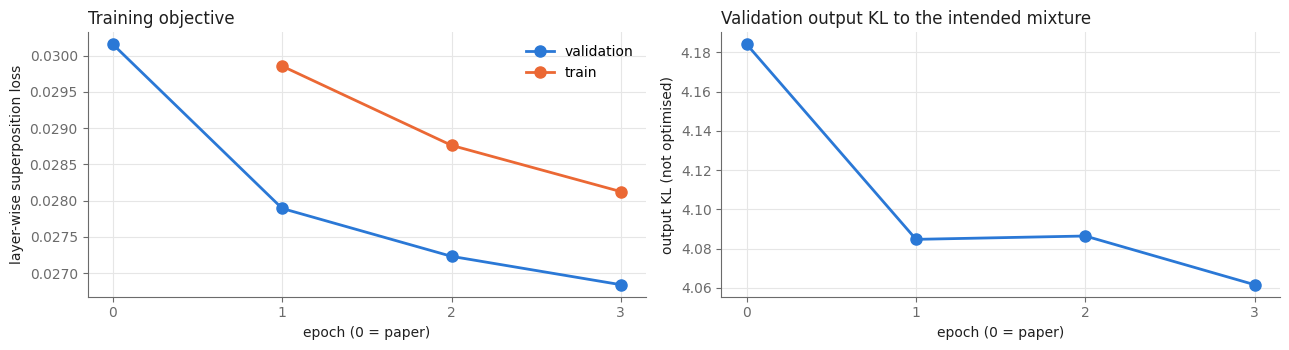

In [16]:
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1f1f1f", "#6b6b6b", "#e6e6e6"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
                     "axes.titlelocation": "left", "axes.titlecolor": INK})

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
ax = axes[0]
ax.plot(hist["epoch"], hist["val_loss"], color=BLUE, linewidth=2, marker="o", markersize=8, label="validation")
ax.plot(hist["epoch"][1:], hist["train_loss"][1:], color=ORANGE, linewidth=2, marker="o", markersize=8, label="train")
ax.set_xticks(hist["epoch"]); ax.set_xlabel("epoch (0 = paper)"); ax.set_ylabel("layer-wise superposition loss")
ax.set_title("Training objective"); ax.legend(frameon=False)
ax = axes[1]
ax.plot(hist["epoch"], hist["val_kl"], color=BLUE, linewidth=2, marker="o", markersize=8)
ax.set_xticks(hist["epoch"]); ax.set_xlabel("epoch (0 = paper)"); ax.set_ylabel("output KL (not optimised)")
ax.set_title("Validation output KL to the intended mixture")
plt.tight_layout(); plt.show()

## 4.3 On-policy check

Validation above is *teacher-forced*: it uses prefixes generated without the adapter. During real generation the adapter also shapes every earlier step, so before the long test run we decode held-out training questions with it and compare against the paper's method on the same questions. The guard warns about collapse symptoms (Cold Stop loops or a large accuracy drop); the notebook still runs to the end and reports the outcome.

In [17]:
check_items = val_items[:CFG.n_policy_check]
check_set = [{"id": r["id"], "q": r["q"], "a": r["gold"]} for r in check_items]
check_adapter = run_soft_thinking(check_set, "policy_check", adapter=adapter)
check_table = pd.DataFrame([summarize(check_items, "Soft Thinking (paper)"),
                            summarize(check_adapter, "+ concept adapter")]).set_index("system")
display(check_table.round(3))
collapsed = (check_table.loc["+ concept adapter", "stop: cold stop"] > 0.3 or
             check_table.loc["+ concept adapter", "accuracy"] < check_table.loc["Soft Thinking (paper)", "accuracy"] - 0.2)
print("WARNING: collapse symptoms on held-out questions." if collapsed else "On-policy check passed.")

[policy_check]   16/16 | batch  327.4s | elapsed   5.5 min | running acc 0.875


,accuracy,avg think tokens,stop: </think>,stop: cold stop,stop: budget,no \boxed answer,mixed steps,tail repetition
system,,,,,,,,
Soft Thinking (paper),0.875,1083.5,0.875,0.0,0.125,0.125,0.193,0.155
+ concept adapter,0.875,1000.0,0.938,0.0,0.062,0.125,0.181,0.153


On-policy check passed.


---
# Part 5: Evaluation on the GSM8K test questions

The questions and Soft Thinking settings are identical to Notebook 1; the only change is `adapter=adapter`. We then diagnose the new traces **with the adapter applied to their inputs**, so the gap is measured during real generation.

In [18]:
adapter_test = run_soft_thinking(test_set, "adapter_test", adapter=adapter)
diag_adapter = diagnose_run(adapter_test, "diag_adapter", adapter=adapter)

[adapter_test]   16/250 | batch  320.6s | elapsed   5.3 min | running acc 0.875
[adapter_test]   32/250 | batch  298.9s | elapsed  10.3 min | running acc 0.906
[adapter_test]   48/250 | batch  323.3s | elapsed  15.7 min | running acc 0.875
[adapter_test]   64/250 | batch  304.3s | elapsed  20.8 min | running acc 0.875
[adapter_test]   80/250 | batch  322.7s | elapsed  26.2 min | running acc 0.863
[adapter_test]   96/250 | batch  316.5s | elapsed  31.4 min | running acc 0.854
[adapter_test]  112/250 | batch  294.2s | elapsed  36.3 min | running acc 0.866
[adapter_test]  128/250 | batch  321.6s | elapsed  41.7 min | running acc 0.859
[adapter_test]  144/250 | batch  291.9s | elapsed  46.6 min | running acc 0.875
[adapter_test]  160/250 | batch  297.1s | elapsed  51.5 min | running acc 0.856
[adapter_test]  176/250 | batch  288.6s | elapsed  56.3 min | running acc 0.864
[adapter_test]  192/250 | batch  324.4s | elapsed  61.7 min | running acc 0.865
[adapter_test]  208/250 | batch  322.1s 

---
# Part 6: Comparison: paper vs concept adapter

## 6.1 Accuracy and reasoning behaviour

In [19]:
NAMES = ("Soft Thinking (paper)", "+ concept adapter (ours)")
main_table = pd.DataFrame([summarize(paper_test, NAMES[0]), summarize(adapter_test, NAMES[1])]).set_index("system")
main_table.round(3)

,accuracy,avg think tokens,stop: </think>,stop: cold stop,stop: budget,no \boxed answer,mixed steps,tail repetition
system,,,,,,,,
Soft Thinking (paper),0.892,1342.180,0.720,0.0,0.280,0.036,0.214,0.174
+ concept adapter (ours),0.876,1358.992,0.712,0.0,0.288,0.048,0.217,0.168


## 6.2 Superposition gap during real generation

In [20]:
gap_table = pd.DataFrame([diag_summary(diag_paper, NAMES[0]), diag_summary(diag_adapter, NAMES[1])]).set_index("system").T
gap_table["relative change"] = (gap_table[NAMES[1]] - gap_table[NAMES[0]]) / gap_table[NAMES[0]].abs().replace(0, np.nan)
gap_table.round(4)

system,Soft Thinking (paper),+ concept adapter (ours),relative change
mixed steps probed,15909.0000,15943.0000,0.0021
norm ratio (mean),0.8515,0.8466,-0.0058
input shift (mean),0.0002,0.1275,616.8866
"gap, all layers (mean)",0.1425,0.1328,-0.0677
"gap, final layer (mean)",0.2055,0.1978,-0.0375
"dist to top-1, final layer (mean)",0.0786,0.0801,0.0191
closer to top-1 than to superposition,0.9008,0.8952,-0.0062
output KL (mean),4.1950,4.0140,-0.0431
output KL (median),2.7976,2.6600,-0.0492
argmax agrees with mixture,0.9272,0.9307,0.0038


## 6.3 Paired statistical tests (same questions)

* **Accuracy:** an exact McNemar test on the questions where exactly one system is correct.
* **Gap:** a Wilcoxon signed-rank test on the per-question mean gap (all layers) and mean output KL, over questions with mixed steps in both runs.

In [21]:
from math import comb
from scipy.stats import wilcoxon

a = {r["id"]: r for r in paper_test}
b = {r["id"]: r for r in adapter_test}
ids = sorted(set(a) & set(b))
both = sum(a[i]["correct"] and b[i]["correct"] for i in ids)
only_paper = sum(a[i]["correct"] and not b[i]["correct"] for i in ids)
only_ours = sum(b[i]["correct"] and not a[i]["correct"] for i in ids)
neither = len(ids) - both - only_paper - only_ours
n_disc = only_paper + only_ours
p_mcnemar = min(1.0, 2 * sum(comb(n_disc, k) for k in range(min(only_paper, only_ours) + 1)) / 2 ** n_disc) if n_disc else 1.0
paired_table = pd.DataFrame([[both, only_paper], [only_ours, neither]],
                            index=["paper correct", "paper wrong"], columns=["adapter correct", "adapter wrong"])
display(paired_table)
print(f"paper-only correct {only_paper} | adapter-only correct {only_ours} | exact McNemar p = {p_mcnemar:.3f}")

dt = np.array([b[i]["think_tokens"] - a[i]["think_tokens"] for i in ids])
print(f"thinking tokens (adapter - paper): mean {dt.mean():+.1f}, median {np.median(dt):+.0f}")

pq = pd.concat({NAMES[0]: diag_paper.groupby("id")[["gap_layers", "kl_output"]].mean(),
                NAMES[1]: diag_adapter.groupby("id")[["gap_layers", "kl_output"]].mean()}, axis=1).dropna()
tests = []
for metric in ("gap_layers", "kl_output"):
    x, y = pq[(NAMES[0], metric)], pq[(NAMES[1], metric)]
    stat, p = wilcoxon(y, x)
    tests.append({"metric (per-question mean)": metric, "questions": len(pq), "paper": x.mean(), "adapter": y.mean(),
                  "adapter lower on": f"{(y < x).mean():.0%} of questions", "Wilcoxon p": p})
gap_tests = pd.DataFrame(tests)
gap_tests.round(4)

,adapter correct,adapter wrong
paper correct,212,11
paper wrong,7,20


paper-only correct 11 | adapter-only correct 7 | exact McNemar p = 0.481
thinking tokens (adapter - paper): mean +16.8, median +0


,metric (per-question mean),questions,paper,adapter,adapter lower on,Wilcoxon p
0,gap_layers,250,0.1425,0.1328,74% of questions,0.0000
1,kl_output,250,4.1959,4.0136,60% of questions,0.0003


## 6.4 Where the gap closes, and the distributions

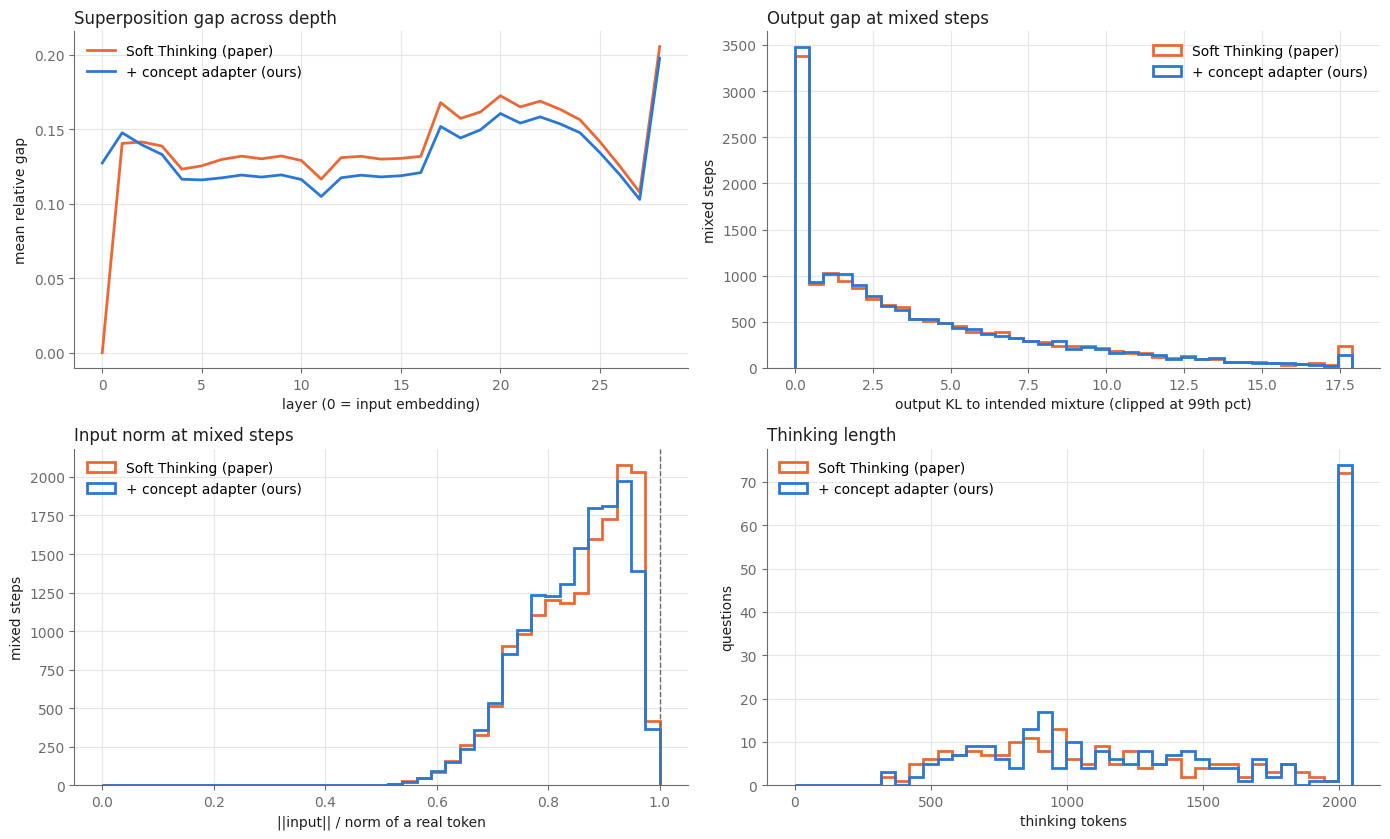

In [22]:
layer_cols = [c for c in diag_paper.columns if c.startswith("gap_L")]
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))

ax = axes[0, 0]
for name, d, c in ((NAMES[0], diag_paper, ORANGE), (NAMES[1], diag_adapter, BLUE)):
    ax.plot(range(len(layer_cols)), d[layer_cols].mean().values, color=c, linewidth=2, label=name)
ax.set_xlabel("layer (0 = input embedding)"); ax.set_ylabel("mean relative gap")
ax.set_title("Superposition gap across depth"); ax.legend(frameon=False)

def step_hists(ax, series, xlabel, title, q=0.99):
    hi = float(np.quantile(np.concatenate([np.asarray(v, dtype=float) for _, v, _ in series]), q))
    bins = np.linspace(0, hi, 40)
    for name, v, c in series:
        ax.hist(np.clip(np.asarray(v, dtype=float), 0, hi), bins=bins, histtype="step", linewidth=2, color=c, label=name)
    ax.set_xlabel(xlabel); ax.set_title(title); ax.legend(frameon=False)

step_hists(axes[0, 1], [(NAMES[0], diag_paper["kl_output"], ORANGE), (NAMES[1], diag_adapter["kl_output"], BLUE)],
           "output KL to intended mixture (clipped at 99th pct)", "Output gap at mixed steps")
axes[0, 1].set_ylabel("mixed steps")
step_hists(axes[1, 0], [(NAMES[0], diag_paper["norm_ratio"], ORANGE), (NAMES[1], diag_adapter["norm_ratio"], BLUE)],
           "||input|| / norm of a real token", "Input norm at mixed steps", q=1.0)
axes[1, 0].axvline(1.0, color=MUTED, linestyle="--", linewidth=1); axes[1, 0].set_ylabel("mixed steps")
step_hists(axes[1, 1], [(NAMES[0], [r["think_tokens"] for r in paper_test], ORANGE),
                        (NAMES[1], [r["think_tokens"] for r in adapter_test], BLUE)],
           "thinking tokens", "Thinking length", q=1.0)
axes[1, 1].set_ylabel("questions")
plt.tight_layout(); plt.show()

## 6.5 Cost of the adapter

In [23]:
adapter_time = json.load(open(f"{OUT_DIR}/adapter_test_time.json")) if os.path.exists(f"{OUT_DIR}/adapter_test_time.json") else None
traces_time = json.load(open(f"{OUT_DIR}/train_traces_time.json")) if os.path.exists(f"{OUT_DIR}/train_traces_time.json") else None
cost = pd.DataFrame([
    {"item": "trainable parameters", "paper": 0, "ours": N_ADAPTER_PARAMS},
    {"item": "frozen LLM parameters", "paper": f"{sum(p.numel() for p in model.parameters())/1e9:.2f}B", "ours": "same"},
    {"item": "labels needed", "paper": "none", "ours": "none"},
    {"item": "trace collection (min)", "paper": 0, "ours": round(traces_time["seconds"] / 60, 1) if traces_time else "n/a"},
    {"item": "adapter training (min)", "paper": 0, "ours": round(train_seconds / 60, 1)},
    {"item": "test decoding (min)", "paper": round(paper_time["seconds"] / 60, 1) if paper_time else "n/a",
     "ours": round(adapter_time["seconds"] / 60, 1) if adapter_time else "n/a"},
]).set_index("item")
cost

,paper,ours
item,,
trainable parameters,0,264256
frozen LLM parameters,1.72B,same
labels needed,none,none
trace collection (min),0,126.8
adapter training (min),0,18.4
test decoding (min),82.6,80.8


---
# Part 7: Conclusion

In [24]:
m, g = main_table, gap_table
acc_p, acc_o = m.loc[NAMES[0], "accuracy"], m.loc[NAMES[1], "accuracy"]
print(f"""ACCURACY
  paper {acc_p:.1%} vs adapter {acc_o:.1%} ({(acc_o-acc_p)*100:+.1f} points) on {len(ids)} questions
  paper-only correct {only_paper}, adapter-only correct {only_ours}, exact McNemar p = {p_mcnemar:.3f}

REASONING BEHAVIOUR
  avg thinking tokens {m.loc[NAMES[0], 'avg think tokens']:.0f} -> {m.loc[NAMES[1], 'avg think tokens']:.0f}
  Cold Stop {m.loc[NAMES[0], 'stop: cold stop']:.1%} -> {m.loc[NAMES[1], 'stop: cold stop']:.1%} | budget {m.loc[NAMES[0], 'stop: budget']:.1%} -> {m.loc[NAMES[1], 'stop: budget']:.1%}
  tail repetition {m.loc[NAMES[0], 'tail repetition']:.3f} -> {m.loc[NAMES[1], 'tail repetition']:.3f} | no boxed answer {m.loc[NAMES[0], 'no \\boxed answer']:.1%} -> {m.loc[NAMES[1], 'no \\boxed answer']:.1%}

SUPERPOSITION GAP (during real generation)
  all layers  {g.loc['gap, all layers (mean)', NAMES[0]]:.4f} -> {g.loc['gap, all layers (mean)', NAMES[1]]:.4f} ({g.loc['gap, all layers (mean)', 'relative change']:+.1%}), Wilcoxon p = {gap_tests.loc[0, 'Wilcoxon p']:.2g}
  final layer {g.loc['gap, final layer (mean)', NAMES[0]]:.4f} -> {g.loc['gap, final layer (mean)', NAMES[1]]:.4f} ({g.loc['gap, final layer (mean)', 'relative change']:+.1%})
  output KL   {g.loc['output KL (mean)', NAMES[0]]:.3f} -> {g.loc['output KL (mean)', NAMES[1]]:.3f} ({g.loc['output KL (mean)', 'relative change']:+.1%}), Wilcoxon p = {gap_tests.loc[1, 'Wilcoxon p']:.2g}
  closer to top-1 than to superposition {g.loc['closer to top-1 than to superposition', NAMES[0]]:.1%} -> {g.loc['closer to top-1 than to superposition', NAMES[1]]:.1%}

COST
  {N_ADAPTER_PARAMS:,} trainable parameters (LLM frozen), no labels, {train_seconds/60:.0f} min of adapter training""")

main_table.to_csv(f"{OUT_DIR}/comparison_results.csv")
gap_table.to_csv(f"{OUT_DIR}/comparison_gap.csv")
gap_tests.to_csv(f"{OUT_DIR}/comparison_tests.csv", index=False)
hist.to_csv(f"{OUT_DIR}/adapter_history.csv", index=False)
check_table.to_csv(f"{OUT_DIR}/policy_check.csv")
with open(f"{OUT_DIR}/config.json", "w") as f:
    json.dump({"run_mode": RUN_MODE, "model": MODEL_NAME, "notebook1_dir": NB1_DIR, **asdict(CFG)}, f, indent=2)
print("\nsaved:", sorted(os.listdir(OUT_DIR)))

ACCURACY
  paper 89.2% vs adapter 87.6% (-1.6 points) on 250 questions
  paper-only correct 11, adapter-only correct 7, exact McNemar p = 0.481

REASONING BEHAVIOUR
  avg thinking tokens 1342 -> 1359
  Cold Stop 0.0% -> 0.0% | budget 28.0% -> 28.8%
  tail repetition 0.174 -> 0.168 | no boxed answer 3.6% -> 4.8%

SUPERPOSITION GAP (during real generation)
  all layers  0.1425 -> 0.1328 (-6.8%), Wilcoxon p = 3.6e-17
  final layer 0.2055 -> 0.1978 (-3.7%)
  output KL   4.195 -> 4.014 (-4.3%), Wilcoxon p = 0.0003
  closer to top-1 than to superposition 90.1% -> 89.5%

COST
  264,256 trainable parameters (LLM frozen), no labels, 18 min of adapter training

saved: ['adapter.pt', 'adapter_history.csv', 'adapter_test.pkl', 'adapter_test_time.json', 'comparison_gap.csv', 'comparison_results.csv', 'comparison_tests.csv', 'config.json', 'diag_adapter.pkl', 'policy_check.csv', 'policy_check.pkl', 'policy_check_time.json', 'train_traces.pkl', 'train_traces_time.json']


**Interpretation.** Read the summary above against the paper's numbers in Notebook 1.

* **Accuracy.** The adapter's goal is to preserve accuracy, not to beat it. A small difference with a large McNemar p-value means the two systems are statistically indistinguishable on GSM8K.
* **The gap.** The adapter moves the model's response toward the superposition Soft Thinking intends. The Wilcoxon tests say whether the per-question reduction is systematic, and the layer plot shows at which depths it happens.
* **Behaviour.** Thinking length, stop reasons, repetition and answer formatting should stay close to the paper's. That shows the adapter changes *how* concept tokens are read without destabilising generation.

**Trade-offs.**

| | Paper (Soft Thinking) | + concept adapter (ours) |
|---|---|---|
| Training | none | about 0.26M parameters on 400 unlabeled traces (trace collection + training, see the cost table) |
| Inference cost | baseline | one small MLP per mixed step; negligible next to a 1.7B forward pass |
| Superposition gap | baseline | smaller during real generation (see 6.2–6.3) |
| Accuracy | baseline | about the same (see 6.3) |
| Generality | model-agnostic, training-free | trained per model; a new model needs new traces |

**Limitations.**

* One model, one dataset, one seed, and fixed hyperparameters (no tuning, by design).
* The adapter is trained off-policy, on prefixes generated without it.
* The superposition target is a modelling assumption: a smaller gap need not translate into higher accuracy, and at this scale accuracy appears limited by other factors.

**Future work.**

* On-policy retraining, with traces regenerated by the adapter.
* Larger adapters, or adapters conditioned on the candidates.
* Other reasoning models and benchmarks.